In [1]:
!pip install yfinance matplotlib pandas


In [2]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt


In [3]:
# Download 1 year of BTC data (daily)
btc = yf.download("BTC-USD", period="1y", interval="1d")

# Preview first 5 rows
btc.head()


/tmp/ipython-input-2388484055.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc = yf.download("BTC-USD", period="1y", interval="1d")
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2024-09-20,63192.976562,64119.531250,62364.605469,62941.425781,35177164222
2024-09-21,63394.839844,63543.359375,62783.105469,63184.339844,14408616220
2024-09-22,63648.710938,63993.421875,62440.726562,63396.804688,20183348802
2024-09-23,63329.800781,64733.558594,62628.078125,63643.101562,31400285425
2024-09-24,64301.968750,64695.214844,62737.417969,63326.839844,29938335243


In [4]:
# Daily % change
btc["Daily Return"] = btc["Close"].pct_change()

# Show first 10 rows
btc.head(10)


Price,Close,High,Low,Open,Volume,Daily Return
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD,
Date,,,,,,
2024-09-20,63192.976562,64119.531250,62364.605469,62941.425781,35177164222,NaN
2024-09-21,63394.839844,63543.359375,62783.105469,63184.339844,14408616220,0.003194
2024-09-22,63648.710938,63993.421875,62440.726562,63396.804688,20183348802,0.004005
2024-09-23,63329.800781,64733.558594,62628.078125,63643.101562,31400285425,-0.005010
2024-09-24,64301.968750,64695.214844,62737.417969,63326.839844,29938335243,0.015351
2024-09-25,63143.144531,64804.503906,62945.375000,64302.589844,25078377700,-0.018022
2024-09-26,65181.019531,65790.796875,62669.269531,63138.546875,36873129847,0.032274
2024-09-27,65790.664062,66480.695312,64852.992188,65180.664062,32058813449,0.009353


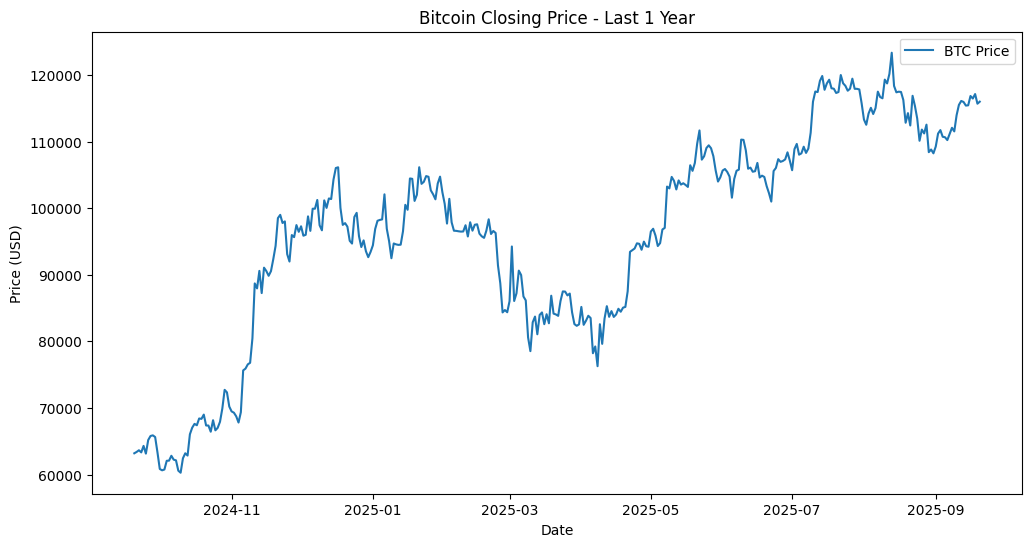

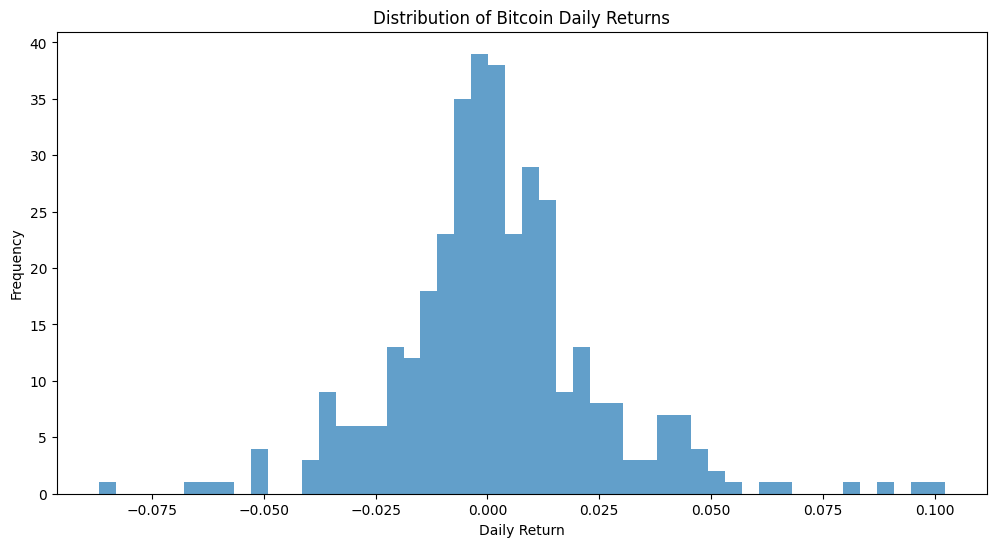

In [5]:
# Closing Price
plt.figure(figsize=(12,6))
plt.plot(btc.index, btc["Close"], label="BTC Price")
plt.title("Bitcoin Closing Price - Last 1 Year")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()

# Daily Returns
plt.figure(figsize=(12,6))
plt.hist(btc["Daily Return"].dropna(), bins=50, alpha=0.7)
plt.title("Distribution of Bitcoin Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.show()


In [6]:
# Download BTC and ETH data for last 1 year
btc = yf.download("BTC-USD", period="1y", interval="1d")
eth = yf.download("ETH-USD", period="1y", interval="1d")

# Add daily returns
btc["Daily Return"] = btc["Close"].pct_change()
eth["Daily Return"] = eth["Close"].pct_change()


/tmp/ipython-input-2167957044.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  btc = yf.download("BTC-USD", period="1y", interval="1d")
[*********************100%***********************]  1 of 1 completed
/tmp/ipython-input-2167957044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  eth = yf.download("ETH-USD", period="1y", interval="1d")
[*********************100%***********************]  1 of 1 completed


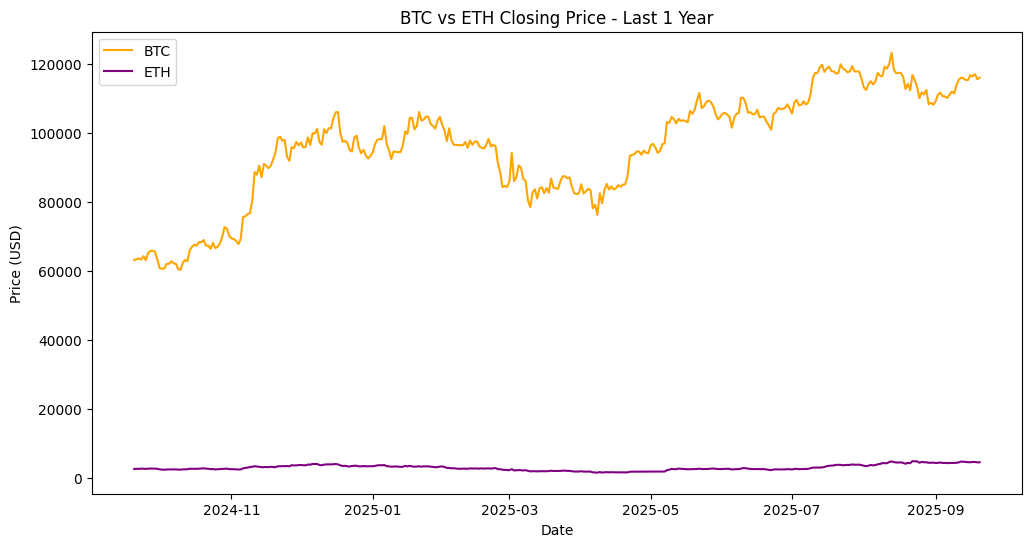

In [7]:
plt.figure(figsize=(12,6))
plt.plot(btc.index, btc["Close"], label="BTC", color="orange")
plt.plot(eth.index, eth["Close"], label="ETH", color="purple")
plt.title("BTC vs ETH Closing Price - Last 1 Year")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.show()


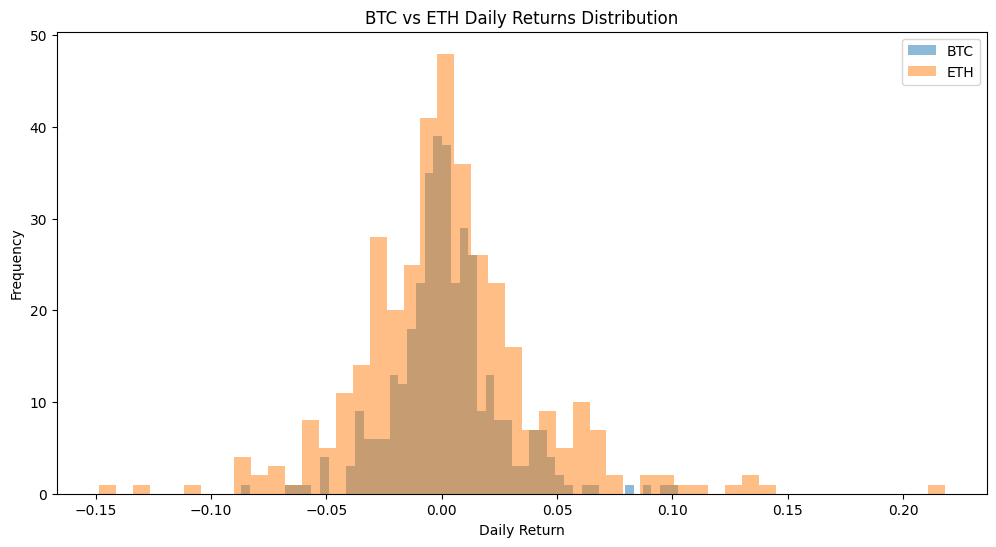

In [8]:
plt.figure(figsize=(12,6))
plt.hist(btc["Daily Return"].dropna(), bins=50, alpha=0.5, label="BTC")
plt.hist(eth["Daily Return"].dropna(), bins=50, alpha=0.5, label="ETH")
plt.title("BTC vs ETH Daily Returns Distribution")
plt.xlabel("Daily Return")
plt.ylabel("Frequency")
plt.legend()
plt.show()


In [10]:
# BTC volatility day
btc_vol_day = btc["Daily Return"].abs().idxmax()
btc_vol_value = float(btc.loc[btc_vol_day, "Daily Return"])

# ETH volatility day
eth_vol_day = eth["Daily Return"].abs().idxmax()
eth_vol_value = float(eth.loc[eth_vol_day, "Daily Return"])

# Print results
print(f"Most volatile BTC day: {btc_vol_day.date()} with return {btc_vol_value:.2%}")
print(f"Most volatile ETH day: {eth_vol_day.date()} with return {eth_vol_value:.2%}")



Most volatile BTC day: 2024-11-11 with return 10.22%
Most volatile ETH day: 2025-05-08 with return 21.80%


/tmp/ipython-input-1111135883.py:3: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  btc_vol_value = float(btc.loc[btc_vol_day, "Daily Return"])
/tmp/ipython-input-1111135883.py:7: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  eth_vol_value = float(eth.loc[eth_vol_day, "Daily Return"])


/tmp/ipython-input-2685639171.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  btc_monthly = btc["Daily Return"].resample("M").mean()
/tmp/ipython-input-2685639171.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  eth_monthly = eth["Daily Return"].resample("M").mean()


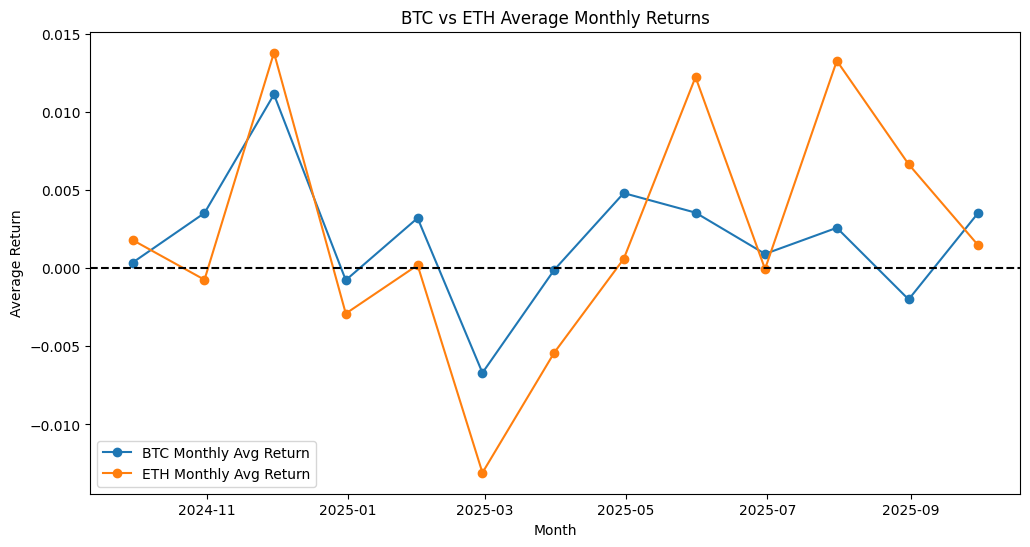

In [11]:
# Resample by month and calculate average return
btc_monthly = btc["Daily Return"].resample("M").mean()
eth_monthly = eth["Daily Return"].resample("M").mean()

# Plot
plt.figure(figsize=(12,6))
plt.plot(btc_monthly.index, btc_monthly, label="BTC Monthly Avg Return", marker="o")
plt.plot(eth_monthly.index, eth_monthly, label="ETH Monthly Avg Return", marker="o")
plt.axhline(0, color="black", linestyle="--")
plt.title("BTC vs ETH Average Monthly Returns")
plt.xlabel("Month")
plt.ylabel("Average Return")
plt.legend()
plt.show()


In [12]:
btc_mean_return = btc["Daily Return"].mean()
eth_mean_return = eth["Daily Return"].mean()

print("BTC Avg Daily Return:", btc_mean_return)
print("ETH Avg Daily Return:", eth_mean_return)


BTC Avg Daily Return: 0.0019309751310317127
ETH Avg Daily Return: 0.002290675491945993


In [13]:
btc_volatility = btc["Daily Return"].std()
eth_volatility = eth["Daily Return"].std()

print("BTC Volatility:", btc_volatility)
print("ETH Volatility:", eth_volatility)


BTC Volatility: 0.02307717890345514
ETH Volatility: 0.0388928691367284


In [14]:
btc_sharpe = btc_mean_return / btc_volatility
eth_sharpe = eth_mean_return / eth_volatility

print("BTC Sharpe Ratio:", btc_sharpe)
print("ETH Sharpe Ratio:", eth_sharpe)


BTC Sharpe Ratio: 0.08367466140944138
ETH Sharpe Ratio: 0.05889705601026997


In [15]:
btc_sharpe_annual = (btc_mean_return / btc_volatility) * (252**0.5)
eth_sharpe_annual = (eth_mean_return / eth_volatility) * (252**0.5)

print("BTC Annualized Sharpe Ratio:", btc_sharpe_annual)
print("ETH Annualized Sharpe Ratio:", eth_sharpe_annual)


BTC Annualized Sharpe Ratio: 1.3282940707614914
ETH Annualized Sharpe Ratio: 0.9349617789420984
